 ### Hard Voting — Multiple Classifiers

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import VotingClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create individual models
lr = LogisticRegression(max_iter=1000)
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
knn = KNeighborsClassifier(n_neighbors=5)
svm = SVC(probability=True, random_state=42)

# Hard Voting
hard_voting = VotingClassifier(
    estimators=[
        ("lr", lr),
        ("dt", dt),
        ("rf", rf),
        ("knn", knn),
        ("svm", svm)
    ],
    voting="hard"
)

# Train
hard_voting.fit(X_train, y_train)

# Predict
y_pred = hard_voting.predict(X_test)

# Evaluation
print("Hard Voting Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Hard Voting Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


### Soft Voting — Probability-Based Voting

In [2]:
soft_voting = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("dt", DecisionTreeClassifier(max_depth=3, random_state=42)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
        ("svm", SVC(probability=True, random_state=42))
    ],
    voting="soft"
)

soft_voting.fit(X_train, y_train)

y_pred_soft = soft_voting.predict(X_test)

print("Soft Voting Accuracy:",
      accuracy_score(y_test, y_pred_soft))

print("\nPredicted probabilities:")
print(soft_voting.predict_proba(X_test[:5]))

print("\nPredicted classes:")
print(iris.target_names[y_pred_soft[:5]])

Soft Voting Accuracy: 0.9666666666666667

Predicted probabilities:
[[0.9915228  0.00644777 0.00202943]
 [0.00263023 0.25662971 0.74074006]
 [0.05284228 0.9046908  0.04246691]
 [0.04434229 0.93764931 0.0180084 ]
 [0.99276613 0.00533059 0.00190328]]

Predicted classes:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa']


### Weighted Soft Voting

In [3]:
weighted_voting = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("dt", DecisionTreeClassifier(max_depth=3, random_state=42)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
        ("svm", SVC(probability=True, random_state=42))
    ],
    voting="soft",
    weights=[1, 1, 3, 2, 2]
)

weighted_voting.fit(X_train, y_train)

y_pred_weighted = weighted_voting.predict(X_test)

print("Weighted Voting Accuracy:",
      accuracy_score(y_test, y_pred_weighted))

Weighted Voting Accuracy: 0.9666666666666667


Logistic Regression: 96.67%
Decision Tree: 96.67%
Random Forest: 90.00%
KNN: 100.00%
SVM: 96.67%
Hard Voting: 96.67%
Soft Voting: 96.67%
Weighted Voting: 96.67%

Model Comparison:
                 Model  Accuracy
3                  KNN  1.000000
0  Logistic Regression  0.966667
1        Decision Tree  0.966667
4                  SVM  0.966667
5          Hard Voting  0.966667
6          Soft Voting  0.966667
7      Weighted Voting  0.966667
2        Random Forest  0.900000


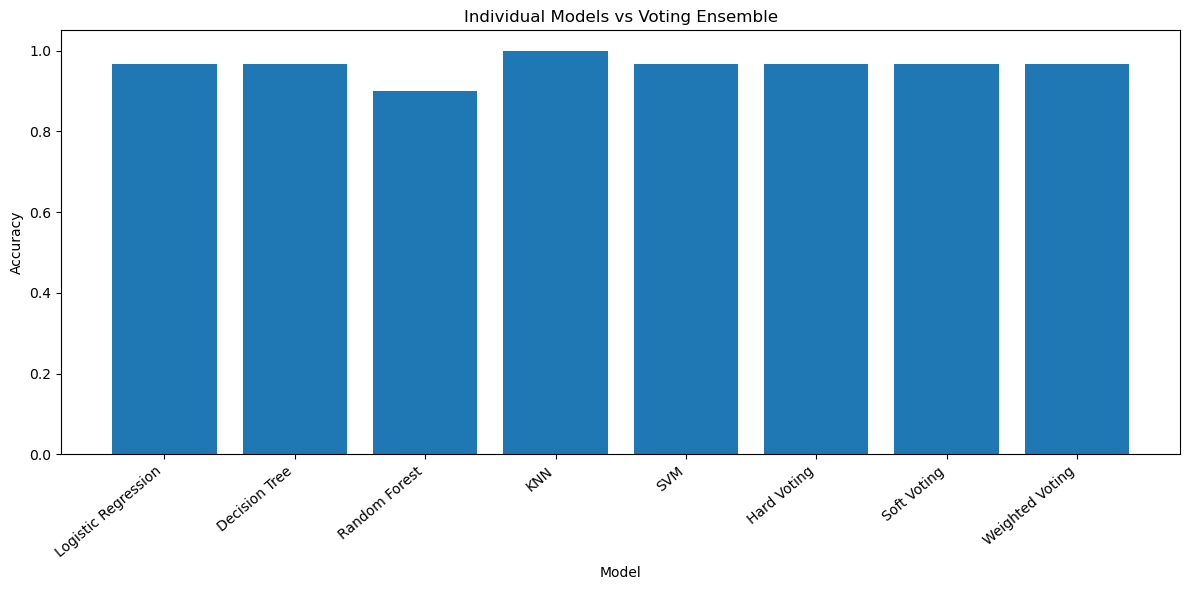

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True, random_state=42),
    "Hard Voting": hard_voting,
    "Soft Voting": soft_voting,
    "Weighted Voting": weighted_voting
}

results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    accuracy = accuracy_score(y_test, prediction)

    results[name] = accuracy

    print(f"{name}: {accuracy * 100:.2f}%")

# Results DataFrame
results_df = pd.DataFrame({
    "Model": results.keys(),
    "Accuracy": results.values()
})

print("\nModel Comparison:")
print(results_df.sort_values(by="Accuracy", ascending=False))

# Visualization
plt.figure(figsize=(12, 6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Individual Models vs Voting Ensemble")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import mode

# Train individual models
model1 = LogisticRegression(max_iter=1000)
model2 = DecisionTreeClassifier(max_depth=3, random_state=42)
model3 = RandomForestClassifier(n_estimators=100, random_state=42)

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)

# Get predictions
pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)
pred3 = model3.predict(X_test)

# Combine predictions
all_predictions = np.array([pred1, pred2, pred3])

# Majority voting
final_predictions = mode(all_predictions, axis=0, keepdims=False).mode

print("Final Predictions:", final_predictions)

print(
    "Custom Voting Accuracy:",
    accuracy_score(y_test, final_predictions)
)

Final Predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]
Custom Voting Accuracy: 0.9666666666666667


### Soft Voting From Scratch

In [6]:
# Train three probability-based models
model1 = LogisticRegression(max_iter=1000)
model2 = DecisionTreeClassifier(max_depth=3, random_state=42)
model3 = RandomForestClassifier(n_estimators=100, random_state=42)

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)

# Get class probabilities
prob1 = model1.predict_proba(X_test)
prob2 = model2.predict_proba(X_test)
prob3 = model3.predict_proba(X_test)

# Average probabilities
average_probabilities = (prob1 + prob2 + prob3) / 3

# Select class with highest probability
final_predictions = np.argmax(average_probabilities, axis=1)

print("Soft Voting Predictions:", final_predictions)

print(
    "Custom Soft Voting Accuracy:",
    accuracy_score(y_test, final_predictions)
)

Soft Voting Predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]
Custom Soft Voting Accuracy: 0.9666666666666667


In [7]:
from sklearn.model_selection import cross_val_score

voting_model = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("dt", DecisionTreeClassifier(max_depth=3, random_state=42)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
        ("svm", SVC(probability=True, random_state=42))
    ],
    voting="soft"
)

scores = cross_val_score(
    voting_model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("Cross Validation Scores:", scores)
print("Mean Accuracy:", scores.mean())
print("Standard Deviation:", scores.std())

Cross Validation Scores: [0.96666667 0.96666667 0.93333333 0.96666667 1.        ]
Mean Accuracy: 0.9666666666666668
Standard Deviation: 0.02108185106778919


In [9]:
from sklearn.model_selection import GridSearchCV

voting_model = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("dt", DecisionTreeClassifier(random_state=42)),
        ("rf", RandomForestClassifier(random_state=42))
    ]
)

params = {
    "voting": ["hard", "soft"],
    "weights": [
        None,
        [1, 1, 1],
        [1, 2, 3],
        [2, 1, 3]
    ],
    "dt__max_depth": [2, 3, 4, None],
    "rf__n_estimators": [50, 100, 200]
}

grid = GridSearchCV(
    estimator=voting_model,
    param_grid=params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

Best Parameters: {'dt__max_depth': 2, 'rf__n_estimators': 50, 'voting': 'hard', 'weights': None}
Best CV Accuracy: 0.9583333333333334
Test Accuracy: 0.9333333333333333


Exception ignored in: <function ResourceTracker.__del__ at 0x106495bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10565dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104991bc0>
Traceback (most recent call last